In [ ]:
import pandas as pd

df = pd.read_csv('samplesuperstore.csv')
df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country/Region,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,US-2023-103800,1/3/2023,1/7/2023,Standard Class,DP-13000,Darren Powers,Consumer,United States,Houston,...,77095,Central,OFF-PA-10000174,Office Supplies,Paper,"Message Book, Wirebound, Four 5 1/2"" X 4"" Form...",16.448,2,0.2,5.5512
1,2,US-2023-112326,1/4/2023,1/8/2023,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,60540,Central,OFF-BI-10004094,Office Supplies,Binders,GBC Standard Plastic Binding Systems Combs,3.540,2,0.8,-5.4870
2,3,US-2023-112326,1/4/2023,1/8/2023,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,60540,Central,OFF-LA-10003223,Office Supplies,Labels,Avery 508,11.784,3,0.2,4.2717
3,4,US-2023-112326,1/4/2023,1/8/2023,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,60540,Central,OFF-ST-10002743,Office Supplies,Storage,SAFCO Boltless Steel Shelving,272.736,3,0.2,-64.7748
4,5,US-2023-141817,1/5/2023,1/12/2023,Standard Class,MB-18085,Mick Brown,Consumer,United States,Philadelphia,...,19143,East,OFF-AR-10003478,Office Supplies,Art,Avery Hi-Liter EverBold Pen Style Fluorescent ...,19.536,3,0.2,4.8840


In [ ]:
print("Total Rows aur Columns:", df.shape)
df.info()

Total Rows aur Columns: (10194, 21)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10194 entries, 0 to 10193
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Row ID          10194 non-null  int64  
 1   Order ID        10194 non-null  object 
 2   Order Date      10194 non-null  object 
 3   Ship Date       10194 non-null  object 
 4   Ship Mode       10194 non-null  object 
 5   Customer ID     10194 non-null  object 
 6   Customer Name   10194 non-null  object 
 7   Segment         10194 non-null  object 
 8   Country/Region  10194 non-null  object 
 9   City            10194 non-null  object 
 10  State/Province  10194 non-null  object 
 11  Postal Code     10194 non-null  object 
 12  Region          10194 non-null  object 
 13  Product ID      10194 non-null  object 
 14  Category        10194 non-null  object 
 15  Sub-Category    10194 non-null  object 
 16  Product Name    10194 non-null  object 


In [ ]:
df.describe()

,Row ID,Sales,Quantity,Discount,Profit
count,10194.000000,10194.000000,10194.000000,10194.000000,10194.000000
mean,5097.500000,228.225854,3.791838,0.155385,28.673417
std,2942.898656,619.906839,2.228317,0.206249,232.465115
min,1.000000,0.444000,1.000000,0.000000,-6599.978000
25%,2549.250000,17.220000,2.000000,0.000000,1.760800
50%,5097.500000,53.910000,3.000000,0.200000,8.690000
75%,7645.750000,209.500000,5.000000,0.200000,29.297925
max,10194.000000,22638.480000,14.000000,0.800000,8399.976000


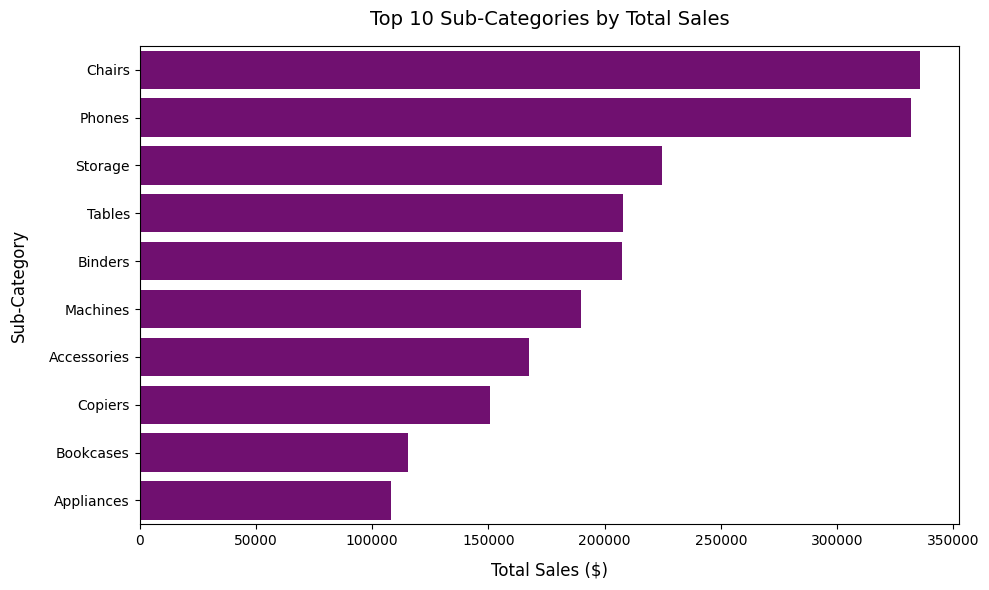

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

top10_products = df.groupby('Sub-Category')['Sales'].sum().nlargest(10).reset_index()

plt.figure(figsize=(10, 6))
sns.barplot(x='Sales', y='Sub-Category', data=top10_products, color='purple')

plt.title('Top 10 Sub-Categories by Total Sales', fontsize=14, pad=15)
plt.xlabel('Total Sales ($)', fontsize=12, labelpad=10)
plt.ylabel('Sub-Category', fontsize=12, labelpad=15)

plt.tight_layout()
plt.show()


### Observation
Phones and Chairs generate the highest revenue among all sub categories, whereas Bookcases make significantly less sales.

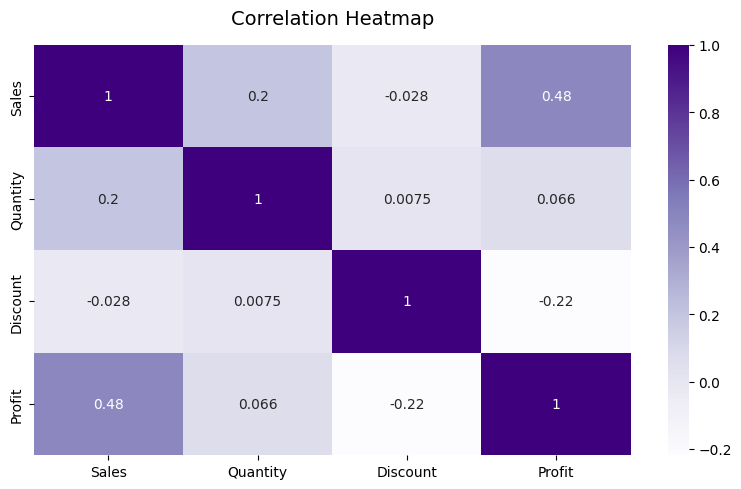

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))
sns.heatmap(df[['Sales', 'Quantity', 'Discount', 'Profit']].corr(), annot=True, cmap='Purples')

plt.title('Correlation Heatmap', fontsize=14, pad=15)
plt.tight_layout()
plt.show()

### Observation
There is a negative correlation (-0.22) between Discount and Profit, showing that offering higher discounts reduces net profit.

In [ ]:
total_sales = df['Sales'].sum()
total_profit = df['Profit'].sum()
avg_discount = df['Discount'].mean() * 100

print("=== BUSINESS SUMMARY ===")
print(f"Total Revenue: ${total_sales:,.2f}")
print(f"Total Profit: ${total_profit:,.2f}")
print(f"Average Discount Given: {avg_discount:.1f}%")

=== BUSINESS SUMMARY ===
Total Revenue: $2,326,534.35
Total Profit: $292,296.81
Average Discount Given: 15.5%


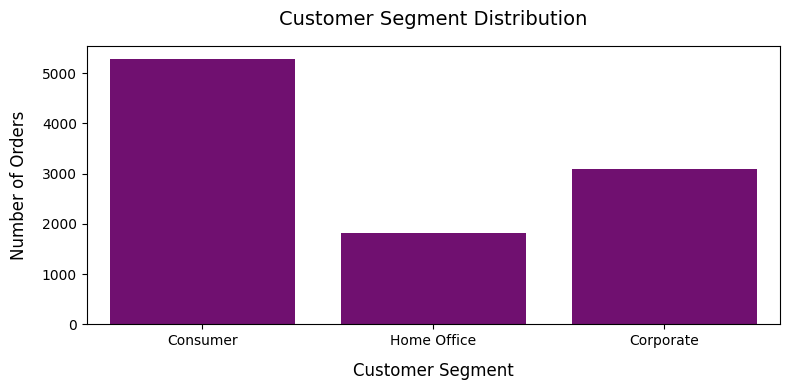

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 4))
sns.countplot(x='Segment', data=df, color='purple')
plt.title('Customer Segment Distribution', fontsize=14, pad=15)
plt.xlabel('Customer Segment', fontsize=12, labelpad=10)
plt.ylabel('Number of Orders', fontsize=12, labelpad=10)
plt.tight_layout()
plt.show()

### Observation
The Consumer segment accounts for the highest number of orders, followed by Corporate and Home Office segments.

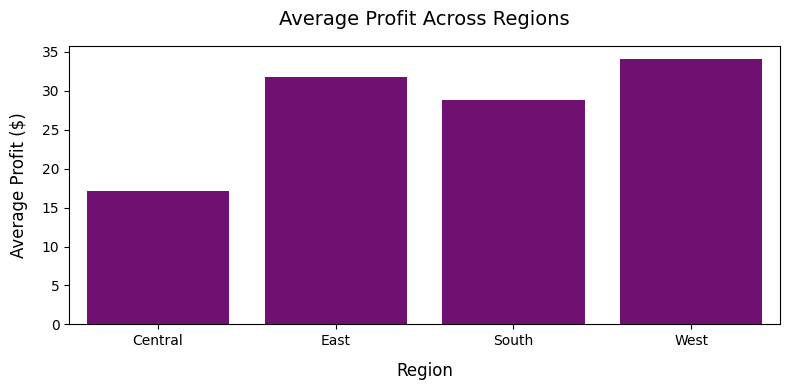

In [ ]:
plt.figure(figsize=(8, 4))
sns.barplot(x='Region', y='Profit', data=df, color='purple', errorbar=None)
plt.title('Average Profit Across Regions', fontsize=14, pad=15)
plt.xlabel('Region', fontsize=12, labelpad=10)
plt.ylabel('Average Profit ($)', fontsize=12, labelpad=10)
plt.tight_layout()
plt.show()

### Observation
Profitability varies across regions with the Central region bringing in lower average profits due to higher discount rates.

## Conclusion & Business Recommendations

1. **Limit Discounts:** Restrict discounts above 20% because offering higher discounts directly reduces overall profit.
2. **Promote High Performers:** Allocate more stock and marketing efforts to top revenue drivers like Phones and Chairs.
3. **Adjust Regional Strategy:** Review pricing and promotional discount policies in underperforming areas like the Central region.